#  Food Ordering Agent — Complete Jury Demo

**Workflow:** User Goal → Understand Request → Plan → Address → Restaurant Search → Constraint Filtering → Rank → Select → Menu → Filter → Rank → Select Item → Customization → Cart → Payment → Confirmation → Order → Tracking → Re-plan.

This notebook uses **Gemini + LangGraph + real Swiggy MCP tools**.

>  A real order is never placed automatically. Explicit user confirmation is required.

## 1. Setup

This notebook is intentionally rebuilt cleanly instead of patching the original 92-cell notebook. It avoids duplicated `AgentState`, duplicate graph nodes, missing routing functions and placeholder nodes.

In [ ]:

# CELL 3 — INSTALL PACKAGES


%pip install -qU \
    langgraph \
    langchain \
    langchain-google-genai \
    google-genai \
    langchain-mcp-adapters==0.3.2 \
    "mcp>=1.29.0,<2" \
    nest_asyncio

In [ ]:

# CELL 4 — IMPORTS


import os
import re
import json
import base64
import hashlib
import secrets
import threading
import time
import webbrowser
import importlib.metadata as package_metadata

from urllib.parse import urlencode, urlparse, parse_qs
from http.server import BaseHTTPRequestHandler, HTTPServer
from typing import TypedDict, Any, Optional

import requests
import nest_asyncio

nest_asyncio.apply()

print("✓ Imports ready")

✓ Imports ready


In [ ]:

# CELL 5 — VERSION CHECK

for package in [
    "langgraph",
    "langchain",
    "langchain-google-genai",
    "google-genai",
    "langchain-mcp-adapters",
    "mcp",
]:
    try:
        print(f"{package}: {package_metadata.version(package)}")
    except Exception:
        print(f"{package}: not found")

langgraph: 1.2.11
langchain: 1.3.18
langchain-google-genai: 4.3.7
google-genai: 2.21.0
langchain-mcp-adapters: 0.3.2
mcp: 1.29.1


## 2. Gemini API key



In [ ]:

# CELL 7 — GEMINI API KEY


import getpass

if not os.environ.get("GEMINI_API_KEY"):
    os.environ["GEMINI_API_KEY"] = getpass.getpass(
        "Enter your GEMINI_API_KEY: "
    )

assert os.environ.get("GEMINI_API_KEY"), "GEMINI_API_KEY is missing."

print("✓ Gemini API key loaded")

✓ Gemini API key loaded


In [4]:
from google import genai

client = genai.Client()

response = client.models.generate_content(
    model="gemini-3.6-flash",
    contents="Respond with exactly: Gemini connection successful."
)

print(response.text)

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


Gemini connection successful.


## 3. Swiggy MCP OAuth

Swiggy Food MCP uses OAuth. The following cells create a local development client, perform PKCE authorization, receive the callback and obtain a Bearer access token.

In [ ]:

# CELL 10 — SWIGGY MCP OAUTH CONFIGURATION


import base64
import hashlib
import secrets
import threading
import time
import webbrowser

import requests

from http.server import BaseHTTPRequestHandler, HTTPServer
from urllib.parse import urlparse, parse_qs, urlencode


# Swiggy Food MCP endpoint
SWIGGY_MCP_URL = "https://mcp.swiggy.com/food"

# OAuth server
AUTH_BASE = "https://mcp.swiggy.com"

# OAuth redirect URI
REDIRECT_URI = "http://localhost:8765/callback"

# Required MCP scope
SCOPE = "mcp:tools"

print("✓ Swiggy MCP OAuth configuration loaded")
print("MCP URL:", SWIGGY_MCP_URL)
print("Redirect URI:", REDIRECT_URI)

✓ Swiggy MCP OAuth configuration loaded
MCP URL: https://mcp.swiggy.com/food
Redirect URI: http://localhost:8765/callback


In [ ]:

# CELL 11 — GENERATE PKCE VALUES


# PKCE code verifier
code_verifier = (
    base64.urlsafe_b64encode(
        secrets.token_bytes(32)
    )
    .decode()
    .rstrip("=")
)

# PKCE code challenge = BASE64URL(SHA256(code_verifier))
code_challenge = (
    base64.urlsafe_b64encode(
        hashlib.sha256(
            code_verifier.encode("utf-8")
        ).digest()
    )
    .decode()
    .rstrip("=")
)

# OAuth CSRF protection state
state = secrets.token_urlsafe(32)

print("✓ PKCE verifier generated")
print("✓ PKCE challenge generated")
print("✓ OAuth state generated")

✓ PKCE verifier generated
✓ PKCE challenge generated
✓ OAuth state generated


In [ ]:

# CELL 12 — REGISTER SWIGGY OAUTH CLIENT


registration_payload = {
    "client_name": "Food Ordering Agent - Jury Demo",
    "redirect_uris": [REDIRECT_URI],
    "grant_types": ["authorization_code"],
    "response_types": ["code"],
    "token_endpoint_auth_method": "none"
}

registration_response = requests.post(
    f"{AUTH_BASE}/auth/register",
    json=registration_payload,
    timeout=30
)

print(
    "Registration status:",
    registration_response.status_code
)

registration_response.raise_for_status()

client_data = registration_response.json()

# IMPORTANT:
# This creates the exact variable used by Cell 13.
client_id = client_data["client_id"]

print("✓ Swiggy OAuth client registered")
print("✓ client_id received")

Registration status: 201
✓ Swiggy OAuth client registered
✓ client_id received


In [26]:
authorization_params = {
    "response_type": "code",
    "client_id": client_id,
    "redirect_uri": REDIRECT_URI,
    "code_challenge": code_challenge,
    "code_challenge_method": "S256",
    "state": state,
    "scope": SCOPE,
}

authorization_url = (
    f"{AUTH_BASE}/auth/authorize?"
    + urlencode(authorization_params)
)

print("✓ Authorization URL created")
print("Opening Swiggy authentication...")

✓ Authorization URL created
Opening Swiggy authentication...


In [27]:
webbrowser.open(authorization_url)

True

In [28]:
callback_result = {}

class OAuthCallbackHandler(BaseHTTPRequestHandler):

    def do_GET(self):
        query = parse_qs(urlparse(self.path).query)

        callback_result["code"] = query.get("code", [None])[0]
        callback_result["state"] = query.get("state", [None])[0]
        callback_result["error"] = query.get("error", [None])[0]

        self.send_response(200)
        self.send_header("Content-Type", "text/html")
        self.end_headers()

        self.wfile.write(
            b"""
            <html>
            <body>
                <h2>Swiggy authentication received.</h2>
                <p>You can close this browser tab and return to the notebook.</p>
            </body>
            </html>
            """
        )

    def log_message(self, format, *args):
        return


server = HTTPServer(("localhost", 8765), OAuthCallbackHandler)

server_thread = threading.Thread(
    target=server.handle_request,
    daemon=True
)

server_thread.start()

print("✓ Callback server listening")
print("Waiting for Swiggy authorization...")

✓ Callback server listening
Waiting for Swiggy authorization...


In [29]:
time.sleep(1)

print("Callback received.")

if callback_result.get("error"):
    print("OAuth error:", callback_result["error"])

elif callback_result.get("code"):
    print("✓ Authorization code received")

else:
    print("✗ No authorization code received")

Callback received.
✓ Authorization code received


In [ ]:

# CELL 16 — EXCHANGE AUTHORIZATION CODE FOR ACCESS TOKEN


# The authorization code was received by the callback server.
# It is stored in callback_result["code"].

if not callback_result.get("code"):
    raise RuntimeError(
        "No authorization code was received from Swiggy. "
        "Run the authorization flow again."
    )

authorization_code = callback_result["code"]

# Verify OAuth state before exchanging the code
if callback_result.get("state") != state:
    raise RuntimeError(
        "OAuth state mismatch. Stop and restart the OAuth flow."
    )

# Swiggy token endpoint
OAUTH_TOKEN_URL = f"{AUTH_BASE}/auth/token"

# Token exchange payload
token_payload = {
    "grant_type": "authorization_code",
    "code": authorization_code,
    "redirect_uri": REDIRECT_URI,
    "client_id": client_id,
    "code_verifier": code_verifier,
}

print("Exchanging authorization code for Swiggy access token...")

token_response = requests.post(
    OAUTH_TOKEN_URL,
    data=token_payload,
    timeout=30
)

print("Token response status:", token_response.status_code)

# Stop immediately if Swiggy rejects the exchange
token_response.raise_for_status()

token_data = token_response.json()

# Store the access token
swiggy_access_token = token_data["access_token"]

expires_in = token_data.get("expires_in")

print("✓ Swiggy OAuth successful")
print("✓ Access token received")

if expires_in:
    print("✓ Token lifetime:", expires_in, "seconds")

Exchanging authorization code for Swiggy access token...
Token response status: 200
✓ Swiggy OAuth successful
✓ Access token received
✓ Token lifetime: 432000 seconds


## 4. Connect to Swiggy MCP

In [ ]:

# CELL 18 — CONNECT TO SWIGGY MCP


from langchain_mcp_adapters.client import MultiServerMCPClient

# Make sure the OAuth token exists before creating the MCP client
if not swiggy_access_token:
    raise RuntimeError(
        "Swiggy access token is missing. "
        "Run the OAuth token exchange cell first."
    )

# Create the MCP client using the real Swiggy OAuth token
mcp_client = MultiServerMCPClient(
    {
        "swiggy": {
            "transport": "streamable_http",
            "url": SWIGGY_MCP_URL,
            "headers": {
                "Authorization": f"Bearer {swiggy_access_token}"
            },
        }
    }
)

print("✓ Swiggy MCP client created")
print("✓ Bearer authentication configured")

✓ Swiggy MCP client created
✓ Bearer authentication configured


In [ ]:

# CELL 19 — TEST SWIGGY MCP CONNECTION


print("Testing Swiggy MCP connection...")
print("MCP URL:", SWIGGY_MCP_URL)
print("Token available:", bool(swiggy_access_token))

try:
    swiggy_tools = await mcp_client.get_tools()

    print()
    print("✓ MCP connection successful")
    print(f"✓ Discovered {len(swiggy_tools)} tools")

    for tool in swiggy_tools:
        print("-", tool.name)

except Exception as e:
    print()
    print("❌ MCP CONNECTION FAILED")
    print("Exception type:", type(e).__name__)
    print("Exception:", repr(e))

    import traceback
    print("\n--- FINAL TRACEBACK ---")
    traceback.print_exc()

Testing Swiggy MCP connection...
MCP URL: https://mcp.swiggy.com/food
Token available: True

✓ MCP connection successful
✓ Discovered 20 tools
- get_addresses
- create_address
- delete_address
- search_restaurants
- search_menu
- get_restaurant_menu
- get_food_cart
- update_food_cart
- flush_food_cart
- place_food_order
- fetch_food_coupons
- apply_food_coupon
- get_food_orders
- get_food_order_details
- track_food_order
- get_food_delivery_status
- report_error
- get_payment_options
- check_payment_status
- confirm_order


In [ ]:

# CELL 20 — CREATE TOOL MAP


swiggy_tool_map = {
    tool.name: tool
    for tool in swiggy_tools
}

required_tools = [
    "get_addresses",
    "search_restaurants",
    "search_menu",
    "get_restaurant_menu",
    "update_food_cart",
    "get_food_cart",
    "get_payment_options",
    "place_food_order",
    "track_food_order",
]

missing = [
    name for name in required_tools
    if name not in swiggy_tool_map
]

for name in required_tools:
    print(
        "✓" if name in swiggy_tool_map else "✗",
        name
    )

if missing:
    raise RuntimeError(
        f"Required Swiggy tools are missing: {missing}"
    )

print("✓ All required tools available")

✓ get_addresses
✓ search_restaurants
✓ search_menu
✓ get_restaurant_menu
✓ update_food_cart
✓ get_food_cart
✓ get_payment_options
✓ place_food_order
✓ track_food_order
✓ All required tools available


In [ ]:

# CELL 20A — SAFE MCP TOOL INVOCATION


import asyncio


MCP_TOOL_TIMEOUT = 30


async def invoke_mcp(
    tool_name: str,
    arguments: dict,
    timeout: int = MCP_TOOL_TIMEOUT
):
    """
    Centralized Swiggy MCP invocation.

    Every real MCP call goes through this function so that
    a stalled MCP request cannot block the agent forever.
    """

    if tool_name not in swiggy_tool_map:
        raise RuntimeError(
            f"Swiggy MCP tool not available: {tool_name}"
        )

    tool = swiggy_tool_map[tool_name]

    try:
        return await asyncio.wait_for(
            tool.ainvoke(arguments),
            timeout=timeout
        )

    except asyncio.TimeoutError as e:
        raise TimeoutError(
            f"Swiggy MCP tool '{tool_name}' "
            f"timed out after {timeout} seconds."
        ) from e


print("✓ Safe MCP invocation helper loaded")
print(f"✓ MCP timeout: {MCP_TOOL_TIMEOUT} seconds")

✓ Safe MCP invocation helper loaded
✓ MCP timeout: 30 seconds


## 5. Real delivery address

In [ ]:

# CELL 22 — GET ADDRESSES FROM SWIGGY


try:

    address_result = await invoke_mcp(
        "get_addresses",
        {}
    )

    print("✓ Real Swiggy address response received")

    print(
        extract_text(address_result)[:8000]
    )

except Exception as e:

    print("❌ Address retrieval failed")
    print(
        type(e).__name__,
        str(e)
    )

    raise

✓ Real Swiggy address response received
Found 1 saved address (page 1 of 1, showing 1):
1. [Home] Soham: Second last House, Wagholi, Wagholi, Pune, Maharashtra, India (ID: d83jf2v2na8qh76h8peg__ARt92ARpE9YswhL_9cmG50)

Only one saved address is available: d83jf2v2na8qh76h8peg__ARt92ARpE9YswhL_9cmG50. Tell the user which address is being used, then use it without asking for confirmation.

⚠️ A rich UI widget may be shown to the user with this data. Avoid restating everything the widget already displays — instead, provide a brief recommendation or ask what they'd like to do next.


In [ ]:

# CELL 23 — ADDRESS TEXT HELPER + SELECTION


def extract_text(result):

    if result is None:
        return ""

    if isinstance(result, str):
        return result

    if isinstance(result, dict):

        if "text" in result:
            return str(result["text"])

        return "\n".join(
            extract_text(value)
            for value in result.values()
            if isinstance(value, (str, dict, list))
        )

    if isinstance(result, list):
        return "\n".join(
            extract_text(item)
            for item in result
        )

    return str(result)


def extract_first_id(result):

    text = extract_text(result)

    patterns = [
        r"\(ID:\s*([A-Za-z0-9_-]+)\)",
        r'"addressId"\s*:\s*"([^"]+)"',
        r"'addressId'\s*:\s*'([^']+)'",
    ]

    for pattern in patterns:

        match = re.search(
            pattern,
            text
        )

        if match:
            return match.group(1)

    return None


selected_address_id = extract_first_id(
    address_result
)

if not selected_address_id:
    raise RuntimeError(
        "Could not extract an address ID from Swiggy."
    )

print("✓ First real saved address selected for demo")
print("Address ID:", selected_address_id)

✓ First real saved address selected for demo
Address ID: d83jf2v2na8qh76h8peg__ARt92ARpE9YswhL_9cmG50


## 6. Agent state

This is the single final state definition. It is deliberately defined only once to avoid the original notebook's state duplication problems.

In [ ]:

# CELL 25 — AGENT STATE


class AgentState(TypedDict, total=False):

    user_request: str
    requirements: dict

    addresses: Any
    selected_address_id: Optional[str]

    restaurants: Any
    parsed_restaurants: list
    filtered_restaurants: list
    ranked_restaurants: list
    selected_restaurant: dict
    selected_restaurant_id: Optional[str]

    menu_result: Any
    menu_options: list
    filtered_menu_items: list
    ranked_menu_items: list
    selected_item: dict

    customization_result: Any
    selected_customization: dict

    cart_result: Any
    cart: Any

    payment_options: Any
    payment_method: Optional[str]

    user_confirmation: bool

    order_result: Any
    order_id: Optional[str]
    order_status: Optional[str]

    tracking_result: Any

    current_step: str
    needs_user_input: bool
    replanning_required: bool
    error_message: Optional[str]


print("✓ AgentState created")

✓ AgentState created


# 7. UNDERSTAND REQUEST

Gemini extracts the user's actual food and constraints.

**There is no pizza default.**

In [ ]:

# CELL 27 — GEMINI UNDERSTANDING


UNDERSTANDING_PROMPT = r"""
You are the request-understanding component of a food ordering agent.

Return ONLY valid JSON with these keys:

{
  "food": "string",
  "vegetarian": true,
  "max_budget": 500,
  "max_delivery_minutes": 30
}

Rules:
1. Preserve the food requested by the user.
2. Never replace the food with pizza unless pizza was requested.
3. Vegetarian must be true only when requested.
4. Budget is an integer rupee amount or null.
5. Delivery limit is an integer minute amount or null.
6. Do not invent constraints.
"""


def understand_with_gemini(user_request):

    response = gemini_client.models.generate_content(
        model="gemini-3.6-flash",
        contents=(
            UNDERSTANDING_PROMPT
            + "\n\nUSER REQUEST:\n"
            + user_request
        )
    )

    text = response.text.strip()

    text = re.sub(
        r"^```json\s*|\s*```$",
        "",
        text,
        flags=re.IGNORECASE
    ).strip()

    return json.loads(text)


def understand_node(state: AgentState):

    state["current_step"] = "UNDERSTAND"

    state["requirements"] = understand_with_gemini(
        state["user_request"]
    )

    print("🧠 UNDERSTAND")
    print(
        json.dumps(
            state["requirements"],
            indent=2,
            ensure_ascii=False
        )
    )

    return state

In [ ]:

# CELL 28 — PLAN


def plan_node(state: AgentState):

    state["current_step"] = "PLAN"

    print("🗺️ CREATE TASK PLAN")

    steps = [
        "Get address",
        "Search restaurants",
        "Filter hard constraints",
        "Rank restaurants",
        "Select restaurant",
        "Search menu",
        "Filter menu items",
        "Rank menu items",
        "Select item",
        "Check customization",
        "Update cart",
        "Get payment options",
        "Ask confirmation",
        "Place order",
        "Track order",
    ]

    for i, step in enumerate(steps, 1):
        print(f"{i}. {step}")

    return state

# 8. RESTAURANT SEARCH

In [ ]:

# CELL 30 — REAL RESTAURANT SEARCH


async def restaurant_search_node(
    state: AgentState
):

    state["current_step"] = "SEARCH_RESTAURANTS"

    requirements = state.get(
        "requirements",
        {}
    )

    food = str(
        requirements.get(
            "food",
            ""
        )
    ).strip()

    address_id = state.get(
        "selected_address_id"
    )

    print("🍽️ SEARCH RESTAURANTS")
    print("Search query:", food)

    
    # Validate address
    

    if not address_id:

        print(
            "❌ No delivery address selected."
        )

        state["restaurants"] = []
        state["replanning_required"] = True

        return state

    
    # Real Swiggy MCP search
    

    try:

        result = await invoke_mcp(
            "search_restaurants",
            {
                "addressId": address_id,
                "query": food,
                "offset": 0
            }
        )

    except Exception as e:

        print(
            "❌ Restaurant search failed:",
            type(e).__name__,
            str(e)
        )

        state["restaurants"] = []
        state["replanning_required"] = True
        state["error_message"] = str(e)

        return state

    
    # Store raw Swiggy response
    

    state["restaurants"] = result

    print(
        "✓ Real Swiggy restaurant search completed"
    )

    return state

In [ ]:

# CELL 31 — PARSE SWIGGY RESTAURANTS


def parse_restaurant_response(result):

    data = None

    # Swiggy MCP returns a list like:
    # [
    #   {
    #       "type": "text",
    #       "text": '{"restaurants":[...]}'
    #   }
    # ]

    if isinstance(result, list):

        for block in result:

            if (
                isinstance(block, dict)
                and block.get("type") == "text"
            ):

                text = str(
                    block.get("text", "")
                ).strip()

                if not text:
                    continue

                
                # ignores anything that appears after it.
                try:

                    decoder = json.JSONDecoder()

                    data, _ = decoder.raw_decode(text)

                    if isinstance(data, dict):
                        break

                except json.JSONDecodeError:
                    continue

    # If result is already a dictionary
    elif isinstance(result, dict):

        if "restaurants" in result:
            data = result

        elif result.get("type") == "text":

            text = str(
                result.get("text", "")
            ).strip()

            try:

                decoder = json.JSONDecoder()

                data, _ = decoder.raw_decode(text)

            except json.JSONDecodeError:

                data = None

    # Raw string
    elif isinstance(result, str):

        text = result.strip()

        try:

            decoder = json.JSONDecoder()

            data, _ = decoder.raw_decode(text)

        except json.JSONDecodeError:

            data = None

    
    # Validate
    

    if not isinstance(data, dict):

        print("⚠️ Could not parse Swiggy response")

        return []

    restaurants_raw = data.get(
        "restaurants",
        []
    )

    if not isinstance(restaurants_raw, list):

        return []

    
    # Normalize
    

    restaurants = []

    for r in restaurants_raw:

        if not isinstance(r, dict):
            continue

        name = str(
            r.get("name", "")
        ).strip()

        restaurant_id = str(
            r.get("id", "")
        ).strip()

        cuisines = r.get(
            "cuisines",
            []
        )

        if isinstance(cuisines, list):

            cuisine_text = ", ".join(
                str(c)
                for c in cuisines
            )

        else:

            cuisine_text = str(
                cuisines
            )

        rating = float(
            r.get("avgRating") or 0
        )

        delivery = r.get(
            "deliveryTimeMinutes"
        )

        if delivery is None:
            delivery = 999

        cost_for_two = str(
            r.get("costForTwo", "")
        )

        price_match = re.search(
            r"₹\s*([\d,]+)",
            cost_for_two
        )

        price_for_two = (

            float(
                price_match
                .group(1)
                .replace(",", "")
            )

            if price_match

            else None
        )

        availability = str(
            r.get(
                "availabilityStatus",
                ""
            )
        ).upper()

        restaurants.append({

            "name": (
                name
                .replace("(Ad)", "")
                .strip()
            ),

            "cuisine": cuisine_text,

            "rating": rating,

            "delivery_minutes": int(
                delivery
            ),

            "price_for_two": price_for_two,

            "restaurant_id": restaurant_id,

            "area": str(
                r.get("areaName", "")
            ),

            "availability_status": availability,

            "is_ad": "(Ad)" in name,

            "veg": bool(
                r.get("veg", False)
            ),

            "raw": r,
        })

    return restaurants


print("✓ Swiggy restaurant parser ready")

✓ Swiggy restaurant parser ready


In [ ]:

# TEST PARSER


parsed_test = parse_restaurant_response(
    restaurant_test
)

print(
    "Restaurants parsed:",
    len(parsed_test)
)

for r in parsed_test:

    print(
        f"- {r['name']} | "
        f"{r['cuisine']} | "
        f"{r['rating']}★ | "
        f"{r['delivery_minutes']} min | "
        f"{r['availability_status']}"
    )

Restaurants parsed: 10
- Burger King | Burgers, American | 4.1★ | 18 min | OPEN
- Merwans Cake Stop | Bakery | 4.0★ | 31 min | OPEN
- Cafe Rova | Pizzas, Continental, North Indian, Cafe | 4.1★ | 52 min | OPEN
- The Food Adda | Snacks, Pizzas, Pastas, Fast Food, Burgers, Cafe, Indian, North Indian, Chaat | 3.9★ | 27 min | OPEN
- RJ's Sandwich | sandwich, Fast Food, Momos, Pizzas, Chinese | 4.3★ | 47 min | OPEN
- Pizza Lover | Pizzas | 0.0★ | 43 min | OPEN
- Chef'S Nation | American, Pizzas, Burgers | 4.5★ | 41 min | OPEN
- Cafe Burger 4Ever | Pizzas, Burgers, Cafe | 4.5★ | 34 min | OPEN
- TTC | South Indian, Maharashtrian, Indian, Snacks, Home Food, Healthy Food, Cafe, Chaat | 5.0★ | 37 min | OPEN
- Sandwich Express | Street Food, Fast Food | 4.3★ | 24 min | OPEN


In [ ]:

# CELL 32 — FILTER RESTAURANTS


import re


def normalize_text(text):
    """
    Normalize text for safe token matching.
    """

    text = str(text or "").lower()

    text = re.sub(
        r"[^a-z0-9]+",
        " ",
        text
    )

    return " ".join(
        text.split()
    )


def restaurant_is_relevant(
    restaurant,
    requested_food
):
    """
    Determine restaurant-level food relevance.

    IMPORTANT:
    Only use actual restaurant identity/cuisine fields.
    Do NOT search the complete raw MCP object because
    unrelated metadata may contain the requested word.
    """

    requested_food = normalize_text(
        requested_food
    )

    if not requested_food:
        return True

    name = normalize_text(
        restaurant.get("name", "")
    )

    cuisine = normalize_text(
        restaurant.get("cuisine", "")
    )

    searchable = " ".join([
        name,
        cuisine
    ])

    # Exact phrase
    if requested_food in searchable:
        return True

    # Dynamic token matching
    words = [
        word
        for word in requested_food.split()
        if len(word) > 2
    ]

    if not words:
        return True

    # At least one meaningful requested food
    # token must occur in restaurant identity/cuisine.
    return any(
        re.search(
            rf"\b{re.escape(word)}\b",
            searchable
        )
        for word in words
    )


def restaurant_filter_node(
    state: AgentState
):

    state["current_step"] = (
        "FILTER_RESTAURANTS"
    )

    print(
        "\n🔎 FILTER RESTAURANTS"
    )

    restaurants = parse_restaurant_response(
        state.get(
            "restaurants",
            []
        )
    )

    state["parsed_restaurants"] = restaurants

    requirements = state.get(
        "requirements",
        {}
    )

    food = str(
        requirements.get(
            "food",
            ""
        )
    ).strip()

    max_delivery = requirements.get(
        "max_delivery_minutes"
    )

    valid = []

    # HARD-CONSTRAINT FILTERING
    

    for restaurant in restaurants:

        name = restaurant.get(
            "name",
            "Unknown"
        )

        delivery_time = restaurant.get(
            "delivery_minutes"
        )

        status = str(
            restaurant.get(
                "availability_status",
                ""
            )
        ).strip().upper()

        
        # 1. DELIVERY TIME
       

        if (
            max_delivery is not None
            and delivery_time is not None
            and delivery_time > max_delivery
        ):

            print(
                f"❌ {name}: "
                f"{delivery_time} min > "
                f"{max_delivery} min"
            )

            continue

        
        # 2. RESTAURANT OPEN
        

        if status == "CLOSED":

            print(
                f"❌ {name}: CLOSED"
            )

            continue

        
        # 3. FOOD RELEVANCE
        

        if not restaurant_is_relevant(
            restaurant,
            food
        ):

            print(
                f"❌ {name}: "
                f"food relevance mismatch"
            )

            continue

        

        valid.append(
            restaurant
        )

    # ----------------------------------------
    # SAVE
    # ----------------------------------------

    state[
        "filtered_restaurants"
    ] = valid

    print(
        "\nRestaurants returned:",
        len(restaurants)
    )

    print(
        "Restaurants after filter:",
        len(valid)
    )

    for restaurant in valid:

        print(
            f"✓ {restaurant.get('name')} | "
            f"{restaurant.get('cuisine')} | "
            f"{restaurant.get('rating')}★ | "
            f"{restaurant.get('delivery_minutes')} min | "
            f"{restaurant.get('availability_status')}"
        )

    

    if not valid:

        state[
            "replanning_required"
        ] = True

        print(
            "⚠️ No restaurant satisfies "
            "the hard constraints."
        )

    return state


print(
    "✓ Restaurant filter loaded"
)

✓ Restaurant filter loaded


In [ ]:

# TEST — RESTAURANT FILTER


print(
    "\nTesting restaurant filter...\n"
)

test_state = dict(
    initial_state
)

test_state["requirements"] = {
    "food": "pizza",
    "vegetarian": True,
    "max_budget": 500,
    "max_delivery_minutes": 30
}

test_state["restaurants"] = (
    restaurant_test
)

filtered_test = (
    restaurant_filter_node(
        test_state
    )
)

print(
    "\nFINAL FILTERED RESTAURANTS:"
)

for restaurant in filtered_test[
    "filtered_restaurants"
]:

    print(
        f"{restaurant['name']} | "
        f"{restaurant['delivery_minutes']} min"
    )


Testing restaurant filter...


🔎 FILTER RESTAURANTS
❌ Burger King: food relevance mismatch
❌ Merwans Cake Stop: 31 min > 30 min
❌ Cafe Rova: 52 min > 30 min
❌ RJ's Sandwich: 47 min > 30 min
❌ Pizza Lover: 43 min > 30 min
❌ Chef'S Nation: 41 min > 30 min
❌ Cafe Burger 4Ever: 34 min > 30 min
❌ TTC: 37 min > 30 min
❌ Sandwich Express: food relevance mismatch

Restaurants returned: 10
Restaurants after filter: 1
✓ The Food Adda | Snacks, Pizzas, Pastas, Fast Food, Burgers, Cafe, Indian, North Indian, Chaat | 3.9★ | 27 min | OPEN

FINAL FILTERED RESTAURANTS:
The Food Adda | 27 min


In [247]:
# ============================================
# CELL 33 — RANK RESTAURANTS
# ============================================

def restaurant_rank_node(state: AgentState):

    state["current_step"] = "RANK_RESTAURANTS"

    restaurants = state["filtered_restaurants"]

    if not restaurants:

        state["replanning_required"] = True

        print(
            "⚠️ No restaurant satisfies the "
            "delivery hard constraint."
        )

        return state

    for r in restaurants:

        # Soft ranking:
        # higher rating + faster delivery.
        r["score"] = (
            r["rating"] * 20
            + max(
                0,
                50 - r["delivery_minutes"]
            )
            + (
                2
                if not r["is_ad"]
                else 0
            )
        )

    ranked = sorted(
        restaurants,
        key=lambda x: x["score"],
        reverse=True
    )

    state["ranked_restaurants"] = ranked

    print("🏆 RANK RESTAURANTS")

    for i, r in enumerate(ranked, 1):

        print(
            f"{i}. {r['name']} | "
            f"{r['rating']}★ | "
            f"{r['delivery_minutes']} min | "
            f"score={r['score']:.1f}"
        )

    return state

In [248]:
# ============================================
# CELL 34 — SELECT RESTAURANT
# ============================================

def restaurant_selection_node(
    state: AgentState
):

    state["current_step"] = "SELECT_RESTAURANT"

    ranked = state["ranked_restaurants"]

    if not ranked:

        state["replanning_required"] = True
        return state

    # Select the highest-ranked restaurant
    # that satisfies the restaurant-level constraints.
    selected = ranked[0]

    state["selected_restaurant"] = selected
    state["selected_restaurant_id"] = (
        selected["restaurant_id"]
    )

    print("👤 RESTAURANT RECOMMENDATION")

    print(
        f"✓ Recommended: {selected['name']}"
    )

    print(
        f"✓ Rating: {selected['rating']}★"
    )

    print(
        f"✓ Estimated delivery: "
        f"{selected['delivery_minutes']} min"
    )

    print(
        "✓ Restaurant-level constraints satisfied"
    )

    return state

# 9. MENU SEARCH + CONSTRAINT FILTERING

The ₹500 constraint is applied to the **actual menu-item price**, not the restaurant's "cost for two".

In [297]:
# ============================================
# CELL 36 — REAL SWIGGY MENU SEARCH
# ============================================

import re


# ============================================
# ROBUST MENU PARSER
# ============================================

def parse_menu_response(result):

    items = []

    if not result:
        return items

    # ----------------------------------------
    # Convert MCP response into text
    # ----------------------------------------

    if isinstance(result, str):

        text = result

    elif isinstance(result, list):

        parts = []

        for block in result:

            if isinstance(block, dict):

                if block.get("type") == "text":

                    parts.append(
                        str(
                            block.get(
                                "text",
                                ""
                            )
                        )
                    )

                elif "text" in block:

                    parts.append(
                        str(
                            block["text"]
                        )
                    )

        text = "\n".join(parts)

        if not text:
            text = extract_text(result)

    elif isinstance(result, dict):

        if "text" in result:

            text = str(
                result["text"]
            )

        else:

            text = extract_text(
                result
            )

    else:

        text = str(result)

    # ----------------------------------------
    # Parse every numbered menu item
    # ----------------------------------------

    for line in text.splitlines():

        line = line.strip()

        match = re.match(
            r"^\s*(\d+)\.\s*(.+)$",
            line
        )

        if not match:
            continue

        item_number = int(
            match.group(1)
        )

        content = match.group(2).strip()

        # ------------------------------------
        # ITEM ID
        # ------------------------------------

        id_match = re.search(
            r"\(ID:\s*([A-Za-z0-9_-]+)\)",
            content,
            re.IGNORECASE
        )

        if not id_match:
            continue

        item_id = id_match.group(1)

        # ------------------------------------
        # PRICE
        # ------------------------------------

        price_match = re.search(
            r"₹\s*([\d,]+(?:\.\d+)?)",
            content
        )

        if not price_match:
            continue

        price = float(
            price_match.group(1)
            .replace(",", "")
        )

        # ------------------------------------
        # VEG / NON-VEG
        #
        # IMPORTANT:
        # Veg does NOT need to be immediately
        # followed by (ID: ...)
        # ------------------------------------

        before_id = content[
            :id_match.start()
        ]

        nonveg_match = re.search(
            r"\|\s*Non[-\s]?Veg\b",
            before_id,
            re.IGNORECASE
        )

        veg_match = re.search(
            r"\|\s*Veg\b",
            before_id,
            re.IGNORECASE
        )

        if nonveg_match:

            is_veg = False
            veg_status = "Non-Veg"

        elif veg_match:

            is_veg = True
            veg_status = "Veg"

        else:

            # Unknown = NOT vegetarian
            is_veg = False
            veg_status = "Unknown"

        # ------------------------------------
        # ITEM NAME
        # ------------------------------------

        name = re.split(
            r"\s*[—-]\s*₹",
            content,
            maxsplit=1
        )[0].strip()

        # ------------------------------------
        # FLAGS
        # ------------------------------------

        lower_line = line.lower()

        is_bestseller = (
            "bestseller"
            in lower_line
        )

        has_variants = (
            "variant"
            in lower_line
        )

        has_addons = (
            "addon"
            in lower_line
            or "add-on"
            in lower_line
        )

        # ------------------------------------
        # NORMALIZED ITEM
        # ------------------------------------

        items.append({

            "name": name,

            "price": price,

            "flags":
                veg_status,

            "is_veg":
                is_veg,

            "is_bestseller":
                is_bestseller,

            "has_variants":
                has_variants,

            "has_addons":
                has_addons,

            "item_id":
                item_id,

            "item_number":
                item_number,

            "raw":
                line
        })

    return items


# ============================================
# REAL SWIGGY MENU SEARCH NODE
# ============================================

async def menu_node(
    state: AgentState
):

    state["current_step"] = (
        "SEARCH_MENU"
    )

    restaurant_id = state.get(
        "selected_restaurant_id"
    )

    address_id = state.get(
        "selected_address_id"
    )

    requirements = state.get(
        "requirements",
        {}
    )

    food = str(
        requirements.get(
            "food",
            ""
        )
    ).strip()

    vegetarian = bool(
        requirements.get(
            "vegetarian",
            False
        )
    )

    print("\n🍕 SEARCH MENU")

    print(
        "Restaurant ID:",
        restaurant_id
    )

    print(
        "Search query:",
        food
    )

    print(
        "Vegetarian:",
        vegetarian
    )

    # ----------------------------------------
    # VALIDATION
    # ----------------------------------------

    if not restaurant_id:

        print(
            "❌ No restaurant selected."
        )

        state[
            "menu_result"
        ] = []

        state[
            "replanning_required"
        ] = True

        return state

    if not address_id:

        print(
            "❌ No address selected."
        )

        state[
            "menu_result"
        ] = []

        state[
            "replanning_required"
        ] = True

        return state

    # ----------------------------------------
    # REAL SWIGGY MCP CALL
    # ----------------------------------------

    try:

        result = await invoke_mcp(

            "search_menu",

            {
                "addressId":
                    address_id,

                "query":
                    food,

                "restaurantIdOfAddedItem":
                    str(
                        restaurant_id
                    ),

                "vegFilter":
                    1
                    if vegetarian
                    else 0,

                "offset":
                    0
            }
        )

        state[
            "menu_result"
        ] = result

        print(
            "✓ Real Swiggy menu search completed"
        )

    except Exception as e:

        print(
            "❌ Menu search failed:",
            type(e).__name__,
            str(e)
        )

        state[
            "menu_result"
        ] = []

        state[
            "replanning_required"
        ] = True

        state[
            "error_message"
        ] = str(e)

        return state

    # ----------------------------------------
    # PARSE MENU
    # ----------------------------------------

    parsed_items = (
        parse_menu_response(
            result
        )
    )

    state[
        "menu_options"
    ] = parsed_items

    print(
        "✓ Menu items parsed:",
        len(parsed_items)
    )

    # ----------------------------------------
    # DISPLAY PARSED ITEMS
    # ----------------------------------------

    for item in parsed_items:

        print(
            f"✓ {item['name']} | "
            f"₹{item['price']:.0f} | "
            f"{'VEG' if item['is_veg'] else 'NON-VEG'} | "
            f"ID: {item['item_id']}"
        )

    # ----------------------------------------
    # EMPTY MENU
    # ----------------------------------------

    if not parsed_items:

        print(
            "⚠️ No menu items could be parsed."
        )

        state[
            "replanning_required"
        ] = True

    return state


print(
    "✓ Cell 36 loaded"
)

print(
    "✓ Single menu parser active"
)

print(
    "✓ Real search_menu MCP call active"
)

✓ Cell 36 loaded
✓ Single menu parser active
✓ Real search_menu MCP call active


In [283]:
# ============================================
# TEST — REAL MENU RESPONSE
# ============================================

menu_test_state = {
    "requirements": {
        "food": "pizza",
        "max_price": 500,
        "dietary": "vegetarian"
    },
    "selected_address_id": selected_address_id,
    "selected_restaurant_id": (
        result["filtered_restaurants"][0]["restaurant_id"]
        if "result" in globals()
        else None
    ),
    "selected_restaurant": (
        result["filtered_restaurants"][0]
        if "result" in globals()
        else None
    )
}

print("Restaurant ID:",
      menu_test_state["selected_restaurant_id"])

menu_test_result = await swiggy_tool_map[
    "search_menu"
].ainvoke({
    "addressId": menu_test_state["selected_address_id"],
    "query": "pizza",
    "restaurantIdOfAddedItem":
        menu_test_state["selected_restaurant_id"],
    "vegFilter": 1,
    "offset": 0
})

print("\nTYPE:")
print(type(menu_test_result))

print("\nRAW MENU RESPONSE:")
print(menu_test_result)

Restaurant ID: 1402738

TYPE:
<class 'list'>

RAW MENU RESPONSE:
[{'type': 'text', 'text': 'Found 10 menu items for "pizza":\n1. Loaded cheese Onion Pizza — ₹150 | Veg (ID: 204632418)\n2. Loaded Paneer Tikka Pizza — ₹290 | Veg (ID: 204632414)\n3. Cheesy Paneer Pizza Combo with Fries & Coke — ₹499 | Veg (ID: 204717126)\n4. Veg Overloaded Pizza (Serve 2 ) — ₹550 | Veg (ID: 207771904)\n5.  Loaded Veggie Supreme Pizza — ₹270 | Veg (ID: 204632415)\n6. 4 in 1 Pizza & Fries+ Thumps — ₹395 | Veg (ID: 204718363)\n7. Double Pizza Feast – Any 2 Corn & Veggie Suprem+ Fries + Cold Drink — ₹650 | Veg (ID: 205805703)\n8. 2 Medium Veg Piza (Loaded Suprem & Panner ) — ₹650 | Veg (ID: 207771784)\n9. Crispy Square Plain Paratha — ₹45 | Veg (ID: 207852128)\n10. Ultimate Veg Feast for 2 – Veggie Supreme + Grilled Sandwich + Drink — ₹449 | Veg (ID: 205806078)\n\n⚠️ A rich UI widget may be shown to the user with this data. Avoid restating everything the widget already displays — instead, provide a brief reco

In [284]:
# ============================================
# TEST CELL — MENU PARSER
# ============================================

parsed_menu_test = parse_menu_response(
    menu_test_result
)

print(
    "Menu items parsed:",
    len(parsed_menu_test)
)

for item in parsed_menu_test:

    print(
        f"- {item['name']} | "
        f"₹{item['price']:.0f} | "
        f"{'VEG' if item['is_veg'] else 'NON-VEG'} | "
        f"ID: {item['item_id']}"
    )

Menu items parsed: 10
- Loaded cheese Onion Pizza | ₹150 | VEG | ID: 204632418
- Loaded Paneer Tikka Pizza | ₹290 | VEG | ID: 204632414
- Cheesy Paneer Pizza Combo with Fries & Coke | ₹499 | VEG | ID: 204717126
- Veg Overloaded Pizza (Serve 2 ) | ₹550 | VEG | ID: 207771904
- Loaded Veggie Supreme Pizza | ₹270 | VEG | ID: 204632415
- 4 in 1 Pizza & Fries+ Thumps | ₹395 | VEG | ID: 204718363
- Double Pizza Feast – Any 2 Corn & Veggie Suprem+ Fries + Cold Drink | ₹650 | VEG | ID: 205805703
- 2 Medium Veg Piza (Loaded Suprem & Panner ) | ₹650 | VEG | ID: 207771784
- Crispy Square Plain Paratha | ₹45 | VEG | ID: 207852128
- Ultimate Veg Feast for 2 – Veggie Supreme + Grilled Sandwich + Drink | ₹449 | VEG | ID: 205806078


In [298]:
# ============================================
# CELL 38 — FILTER MENU ITEMS
# ============================================

def menu_filter_node(
    state: AgentState
):

    state["current_step"] = (
        "FILTER_MENU"
    )

    print(
        "\n🔎 FILTER MENU"
    )

    # ----------------------------------------
    # GET PARSED MENU
    # ----------------------------------------

    items = state.get(
        "menu_options",
        []
    )

    # If menu_options is empty but raw
    # menu_result exists, parse again.
    if not items:

        items = parse_menu_response(
            state.get(
                "menu_result",
                []
            )
        )

    requirements = state.get(
        "requirements",
        {}
    )

    food = str(
        requirements.get(
            "food",
            ""
        )
    ).strip().lower()

    vegetarian = bool(
        requirements.get(
            "vegetarian",
            False
        )
    )

    max_budget = requirements.get(
        "max_budget"
    )

    # ----------------------------------------
    # NORMALIZE REQUEST
    # ----------------------------------------

    food_words = [
        word
        for word in re.findall(
            r"[a-zA-Z]+",
            food
        )
        if len(word) > 2
    ]

    valid = []

    # ----------------------------------------
    # HARD FILTERS
    # ----------------------------------------

    for item in items:

        item_name = str(
            item.get(
                "name",
                ""
            )
        ).lower()

        # ====================================
        # FOOD MATCH
        # ====================================

        if food:

            exact_match = (
                food in item_name
            )

            word_match = (
                bool(food_words)
                and all(
                    re.search(
                        rf"\b{re.escape(word)}\b",
                        item_name
                    )
                    for word in food_words
                )
            )

            if not (
                exact_match
                or word_match
            ):

                continue

        # ====================================
        # VEGETARIAN
        # ====================================

        if vegetarian:

            if not item.get(
                "is_veg",
                False
            ):

                continue

        # ====================================
        # BUDGET
        # ====================================

        price = item.get(
            "price",
            float("inf")
        )

        if (
            max_budget is not None
            and price > max_budget
        ):

            continue

        valid.append(
            item
        )

    # ----------------------------------------
    # REMOVE DUPLICATES
    # ----------------------------------------

    unique = {}

    for item in valid:

        item_id = item.get(
            "item_id"
        )

        if item_id:

            unique[
                item_id
            ] = item

    filtered = list(
        unique.values()
    )

    state[
        "filtered_menu_items"
    ] = filtered

    # ----------------------------------------
    # OUTPUT
    # ----------------------------------------

    print(
        "Menu items found:",
        len(items)
    )

    print(
        "Valid menu items:",
        len(filtered)
    )

    for item in filtered:

        print(
            f"✓ {item['name']} | "
            f"₹{item['price']:.0f} | "
            f"VEG"
        )

    # ----------------------------------------
    # REPLAN ONLY IF NOTHING MATCHES
    # ----------------------------------------

    if not filtered:

        state[
            "replanning_required"
        ] = True

        print(
            "⚠️ No menu item satisfies "
            "all hard constraints."
        )

    else:

        state[
            "replanning_required"
        ] = False

    return state

In [256]:
# ============================================
# CELL 39 — RANK MENU
# ============================================

def menu_rank_node(state: AgentState):

    state["current_step"] = "RANK_MENU"

    items = state["filtered_menu_items"]

    if not items:

        state["replanning_required"] = True

        print(
            "⚠️ No menu item satisfies the "
            "vegetarian + budget constraints."
        )

        return state

    for item in items:

        score = max(
            0,
            100 - item["price"] / 5
        )

        if item["is_bestseller"]:
            score += 20

        if (
            item["has_variants"]
            or item["has_addons"]
        ):
            score += 5

        item["score"] = round(
            score,
            2
        )

    ranked = sorted(
        items,
        key=lambda x: x["score"],
        reverse=True
    )

    state["ranked_menu_items"] = ranked

    print("🏆 RANK MENU")

    for i, item in enumerate(
        ranked[:10],
        1
    ):

        print(
            f"{i}. {item['name']} | "
            f"₹{item['price']:.0f} | "
            f"score={item['score']}"
        )

    return state

In [257]:
# ============================================
# CELL 40 — SELECT ITEM
# ============================================

def item_selection_node(
    state: AgentState
):

    state["current_step"] = "SELECT_ITEM"

    ranked = state["ranked_menu_items"]

    if not ranked:

        state["replanning_required"] = True
        return state

    selected = ranked[0]

    state["selected_item"] = selected

    print("👤 SELECT ITEM")
    print("✓", selected["name"])
    print("✓ Price: ₹", selected["price"])

    return state

# 10. CUSTOMIZATION + CART

In [286]:
# ============================================
# CELL 42 — CUSTOMIZATION
# ============================================

async def customization_node(
    state: AgentState
):

    state["current_step"] = (
        "CUSTOMIZATION"
    )

    item = state.get(
        "selected_item",
        {}
    )

    print(
        "⚙️ CUSTOMIZATION"
    )

    if not item:

        print(
            "❌ No selected item."
        )

        state[
            "replanning_required"
        ] = True

        return state

    try:

        result = await invoke_mcp(
            "search_menu",
            {
                "addressId":
                    state[
                        "selected_address_id"
                    ],

                "query":
                    item["name"],

                "restaurantIdOfAddedItem":
                    str(
                        state[
                            "selected_restaurant_id"
                        ]
                    ),

                "vegFilter":
                    1,

                "offset":
                    0
            }
        )

        state[
            "customization_result"
        ] = result

        state[
            "selected_customization"
        ] = {}

        print(
            "✓ Exact item customization "
            "data retrieved"
        )

    except Exception as e:

        print(
            "⚠️ Customization lookup failed:",
            str(e)
        )

        state[
            "customization_result"
        ] = None

        state[
            "selected_customization"
        ] = {}

    if (
        item.get("has_variants")
        or item.get("has_addons")
    ):

        print(
            "ℹ️ Item supports "
            "variants/add-ons."
        )

        print(
            "Demo continues with the "
            "base/default selection."
        )

    else:

        print(
            "ℹ️ No customization required."
        )

    return state

In [287]:
# ============================================
# CELL 43 — UPDATE CART + GET LIVE CART
# ============================================

async def cart_node(
    state: AgentState
):

    state["current_step"] = "CART"

    item = state.get(
        "selected_item",
        {}
    )

    restaurant = state.get(
        "selected_restaurant",
        {}
    )

    print(
        "🛒 CART"
    )

    if not item:

        print(
            "❌ No item selected."
        )

        state[
            "replanning_required"
        ] = True

        return state

    # ----------------------------------------
    # VARIANT SAFETY
    # ----------------------------------------

    if item.get(
        "has_variants"
    ):

        print(
            "⏸️ Variant selection required."
        )

        state[
            "needs_user_input"
        ] = True

        return state

    # ----------------------------------------
    # UPDATE CART
    # ----------------------------------------

    try:

        cart_result = await invoke_mcp(
            "update_food_cart",
            {
                "restaurantId":
                    state[
                        "selected_restaurant_id"
                    ],

                "addressId":
                    state[
                        "selected_address_id"
                    ],

                "restaurantName":
                    restaurant.get(
                        "name",
                        ""
                    ),

                "cartItems": [
                    {
                        "menu_item_id":
                            item[
                                "item_id"
                            ],

                        "quantity":
                            1
                    }
                ]
            }
        )

        state[
            "cart_result"
        ] = cart_result

        # ------------------------------------
        # GET LIVE CART
        # ------------------------------------

        live_cart = await invoke_mcp(
            "get_food_cart",
            {
                "addressId":
                    state[
                        "selected_address_id"
                    ],

                "restaurantName":
                    restaurant.get(
                        "name",
                        ""
                    )
            }
        )

        state[
            "cart"
        ] = live_cart

        print(
            "✓ Cart updated"
        )

        print(
            "✓ Live cart retrieved"
        )

        state[
            "needs_user_input"
        ] = False

    except Exception as e:

        print(
            "❌ Cart operation failed:",
            type(e).__name__,
            str(e)
        )

        state[
            "error_message"
        ] = str(e)

        state[
            "replanning_required"
        ] = True

    return state

# 11. RE-PLANNING

In [260]:
# ============================================
# CELL 45 — REPLAN
# ============================================

def replan_node(state: AgentState):

    state["current_step"] = "REPLAN"

    print("🔄 REPLAN")

    print(
        "The agent could not satisfy all hard "
        "constraints with the current result."
    )

    print(
        "The correct next action is to ask the "
        "user whether a constraint may be relaxed."
    )

    state["replanning_required"] = False
    state["needs_user_input"] = True

    return state

# 12. PAYMENT

Payment options are retrieved from Swiggy. They are not hardcoded.

In [288]:
# ============================================
# CELL 47 — LIVE PAYMENT OPTIONS
# ============================================

async def payment_node(
    state: AgentState
):

    state["current_step"] = (
        "PAYMENT"
    )

    print(
        "💳 PAYMENT"
    )

    try:

        result = await invoke_mcp(
            "get_payment_options",
            {
                "addressId":
                    state[
                        "selected_address_id"
                    ]
            }
        )

        state[
            "payment_options"
        ] = result

        print(
            "✓ Live payment options retrieved"
        )

    except Exception as e:

        print(
            "❌ Payment options failed:",
            type(e).__name__,
            str(e)
        )

        state[
            "error_message"
        ] = str(e)

        state[
            "needs_user_input"
        ] = True

        return state

    # ----------------------------------------
    # PAYMENT METHOD MUST COME FROM USER
    # ----------------------------------------

    payment_method = state.get(
        "payment_method"
    )

    if not payment_method:

        state[
            "needs_user_input"
        ] = True

        print(
            "⏸️ Waiting for user payment "
            "selection."
        )

        return state

    state[
        "needs_user_input"
    ] = False

    print(
        "✓ Payment method:",
        payment_method
    )

    return state

# 13. ORDER CONFIRMATION

This is the **human-in-the-loop safety boundary**.

The order tool is called only if:
- a supported payment method is selected, and
- the user explicitly confirms.

In [289]:
# ============================================
# CELL 49 — PLACE ORDER
# ============================================

async def order_node(
    state: AgentState
):

    state["current_step"] = (
        "PLACE_ORDER"
    )

    payment_method = state.get(
        "payment_method"
    )

    # ----------------------------------------
    # PAYMENT METHOD VALIDATION
    # ----------------------------------------

    if payment_method not in (
        "UPI",
        "Cash",
        "COD"
    ):

        state[
            "needs_user_input"
        ] = True

        print(
            "⏸️ Valid payment method required."
        )

        return state

    # ----------------------------------------
    # HUMAN CONFIRMATION
    # ----------------------------------------

    if not state.get(
        "user_confirmation",
        False
    ):

        state[
            "needs_user_input"
        ] = True

        print(
            "⏸️ Waiting for explicit "
            "user confirmation."
        )

        print(
            "No real order has been placed."
        )

        return state

    # ----------------------------------------
    # PLACE REAL ORDER
    # ----------------------------------------

    print(
        "📦 PLACE ORDER"
    )

    try:

        arguments = {
            "addressId":
                state[
                    "selected_address_id"
                ],

            "paymentMethod":
                payment_method
        }

        # ------------------------------------
        # UPI SUPPORT
        # ------------------------------------
        #
        # If your payment selection UI has
        # provided an intentApp, preserve it.
        #
        # Otherwise the standard UPI method
        # can still be passed.
        # ------------------------------------

        if payment_method == "UPI":

            intent_app = state.get(
                "intent_app"
            )

            generate_qr = state.get(
                "generate_upi_qr"
            )

            if intent_app:

                arguments[
                    "intentApp"
                ] = intent_app

            elif generate_qr:

                arguments[
                    "generateUPIQR"
                ] = True

        result = await invoke_mcp(
            "place_food_order",
            arguments
        )

    except Exception as e:

        print(
            "❌ Order placement failed:",
            type(e).__name__,
            str(e)
        )

        state[
            "error_message"
        ] = str(e)

        state[
            "order_status"
        ] = "FAILED"

        return state

    state[
        "order_result"
    ] = result

    text = extract_text(
        result
    )

    # ----------------------------------------
    # EXTRACT ORDER ID
    # ----------------------------------------

    order_patterns = [

        r'"orderId"\s*:\s*"([^"]+)"',

        r'"order_id"\s*:\s*"([^"]+)"',

        r"orderId\s*[:=]\s*([A-Za-z0-9_-]+)",

        r"Order ID\s*[:=]\s*([A-Za-z0-9_-]+)"
    ]

    for pattern in order_patterns:

        match = re.search(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        if match:

            state[
                "order_id"
            ] = match.group(1)

            break

    # ----------------------------------------
    # DETECT STATUS
    # ----------------------------------------

    upper_text = text.upper()

    if (
        "PENDING_PAYMENT"
        in upper_text
    ):

        state[
            "order_status"
        ] = "PENDING_PAYMENT"

        state[
            "needs_user_input"
        ] = True

        print(
            "⏸️ UPI payment is pending."
        )

        print(
            "Complete payment in the "
            "UPI flow before the order "
            "can be finalized."
        )

        print(
            "Order ID:",
            state.get(
                "order_id"
            )
        )

        return state

    # ----------------------------------------
    # CASH / SUCCESSFUL ORDER
    # ----------------------------------------

    state[
        "order_status"
    ] = "PLACED"

    state[
        "needs_user_input"
    ] = False

    print(
        "✓ Order placed successfully"
    )

    print(
        "Order ID:",
        state.get(
            "order_id"
        )
    )

    return state

In [290]:
# ============================================
# CELL 50 — CHECK UPI PAYMENT STATUS ONCE
# ============================================

async def check_upi_payment_status(
    state: AgentState
):

    order_id = state.get(
        "order_id"
    )

    if not order_id:

        print(
            "❌ No order ID available."
        )

        return state

    order_result = state.get(
        "order_result"
    )

    text = extract_text(
        order_result
    )

    # ----------------------------------------
    # Extract UPI identifiers returned by
    # place_food_order.
    # ----------------------------------------

    def extract_value(
        key
    ):

        match = re.search(
            rf'"{re.escape(key)}"\s*:\s*"([^"]+)"',
            text,
            re.IGNORECASE
        )

        if match:
            return match.group(1)

        return None

    paas_id = extract_value(
        "paasId"
    )

    address_id = (
        state.get(
            "selected_address_id"
        )
    )

    print(
        "💳 CHECK UPI PAYMENT STATUS"
    )

    # NOTE:
    # Swiggy's current Food payment contract
    # uses the identifiers returned by the
    # PENDING_PAYMENT response.
    #
    # Do not invent identifiers.

    arguments = {
        "orderId":
            order_id,

        "addressId":
            address_id
    }

    if paas_id:
        arguments[
            "paasId"
        ] = paas_id

    try:

        result = await invoke_mcp(
            "check_payment_status",
            arguments
        )

        state[
            "payment_status_result"
        ] = result

        print(
            "✓ Payment status retrieved"
        )

        print(
            extract_text(
                result
            )[:4000]
        )

    except Exception as e:

        print(
            "❌ Payment status check failed:",
            type(e).__name__,
            str(e)
        )

    return state

# 14. TRACKING

In [291]:
# ============================================
# CELL 51 — TRACK ORDER
# ============================================

async def tracking_node(
    state: AgentState
):

    state["current_step"] = (
        "TRACK"
    )

    order_id = state.get(
        "order_id"
    )

    if not order_id:

        print(
            "ℹ️ No order ID available "
            "for tracking."
        )

        return state

    print(
        "🚴 TRACK ORDER"
    )

    try:

        result = await invoke_mcp(
            "track_food_order",
            {
                "orderId":
                    order_id
            }
        )

        state[
            "tracking_result"
        ] = result

        print(
            "✓ Live tracking retrieved"
        )

        print(
            extract_text(
                result
            )[:5000]
        )

    except Exception as e:

        print(
            "❌ Tracking failed:",
            type(e).__name__,
            str(e)
        )

        state[
            "error_message"
        ] = str(e)

    return state

# 15. LANGGRAPH

All nodes below are the final implementations above. No placeholder nodes are used.

In [299]:
# ============================================
# CELL 54 — ROUTING FUNCTIONS
# ============================================

def route_after_restaurant_rank(
    state
):

    if state.get(
        "replanning_required"
    ):

        return "replan"

    return "continue"


def route_after_menu_rank(
    state
):

    if state.get(
        "replanning_required"
    ):

        return "replan"

    return "continue"


def route_after_cart(
    state
):

    if state.get(
        "needs_user_input"
    ):

        return "waiting"

    if state.get(
        "replanning_required"
    ):

        return "replan"

    return "payment"


def route_after_payment(
    state
):

    if state.get(
        "needs_user_input"
    ):

        return "waiting"

    return "order"


def route_after_order(
    state
):

    # Never track a failed order.
    if state.get(
        "order_status"
    ) == "FAILED":

        return "end"

    # Never track an unpaid UPI order.
    if state.get(
        "order_status"
    ) == "PENDING_PAYMENT":

        return "end"

    if state.get(
        "order_id"
    ):

        return "tracking"

    return "end"

In [300]:
# ============================================
# CELL 55 — BUILD FINAL GRAPH
# ============================================

from langgraph.graph import (
    StateGraph,
    END
)


builder = StateGraph(
    AgentState
)

# --------------------------------------------
# CORE AGENT NODES
# --------------------------------------------

builder.add_node(
    "understand",
    understand_node
)

builder.add_node(
    "plan",
    plan_node
)

# --------------------------------------------
# RESTAURANT
# --------------------------------------------

builder.add_node(
    "restaurant_search",
    restaurant_search_node
)

builder.add_node(
    "restaurant_filter",
    restaurant_filter_node
)

builder.add_node(
    "restaurant_rank",
    restaurant_rank_node
)

builder.add_node(
    "restaurant_selection",
    restaurant_selection_node
)

# --------------------------------------------
# MENU
# --------------------------------------------

builder.add_node(
    "menu",
    menu_node
)

builder.add_node(
    "menu_filter",
    menu_filter_node
)

builder.add_node(
    "menu_rank",
    menu_rank_node
)

builder.add_node(
    "item_selection",
    item_selection_node
)

# --------------------------------------------
# CUSTOMIZATION + CART
# --------------------------------------------

builder.add_node(
    "customization",
    customization_node
)

builder.add_node(
    "cart",
    cart_node
)

# --------------------------------------------
# PAYMENT + ORDER
# --------------------------------------------

builder.add_node(
    "payment",
    payment_node
)

builder.add_node(
    "order",
    order_node
)

builder.add_node(
    "tracking",
    tracking_node
)

# --------------------------------------------
# REPLAN
# --------------------------------------------

builder.add_node(
    "replan",
    replan_node
)

# --------------------------------------------
# ENTRY
# --------------------------------------------

builder.set_entry_point(
    "understand"
)

# --------------------------------------------
# MAIN FLOW
# --------------------------------------------

builder.add_edge(
    "understand",
    "plan"
)

builder.add_edge(
    "plan",
    "restaurant_search"
)

builder.add_edge(
    "restaurant_search",
    "restaurant_filter"
)

builder.add_edge(
    "restaurant_filter",
    "restaurant_rank"
)

# --------------------------------------------
# RESTAURANT RANK
# --------------------------------------------

builder.add_conditional_edges(

    "restaurant_rank",

    route_after_restaurant_rank,

    {
        "continue":
            "restaurant_selection",

        "replan":
            "replan"
    }
)

builder.add_edge(
    "restaurant_selection",
    "menu"
)

# --------------------------------------------
# MENU
# --------------------------------------------

builder.add_edge(
    "menu",
    "menu_filter"
)

builder.add_edge(
    "menu_filter",
    "menu_rank"
)

builder.add_conditional_edges(

    "menu_rank",

    route_after_menu_rank,

    {
        "continue":
            "item_selection",

        "replan":
            "replan"
    }
)

builder.add_edge(
    "item_selection",
    "customization"
)

builder.add_edge(
    "customization",
    "cart"
)

# --------------------------------------------
# CART
# --------------------------------------------

builder.add_conditional_edges(

    "cart",

    route_after_cart,

    {
        "waiting":
            END,

        "replan":
            "replan",

        "payment":
            "payment"
    }
)

# --------------------------------------------
# PAYMENT
# --------------------------------------------

builder.add_conditional_edges(

    "payment",

    route_after_payment,

    {
        "waiting":
            END,

        "order":
            "order"
    }
)

# --------------------------------------------
# ORDER
# --------------------------------------------

builder.add_conditional_edges(

    "order",

    route_after_order,

    {
        "tracking":
            "tracking",

        "end":
            END
    }
)

# --------------------------------------------
# TRACKING
# --------------------------------------------

builder.add_edge(
    "tracking",
    END
)

# --------------------------------------------
# REPLAN
# --------------------------------------------

builder.add_edge(
    "replan",
    END
)

# --------------------------------------------
# COMPILE
# --------------------------------------------

food_agent = builder.compile()

print(
    "✓ FINAL Food Ordering Agent compiled"
)

print(
    "✓ All updated node functions are active"
)

✓ FINAL Food Ordering Agent compiled
✓ All updated node functions are active


# 16. GRAPH VISUALIZATION

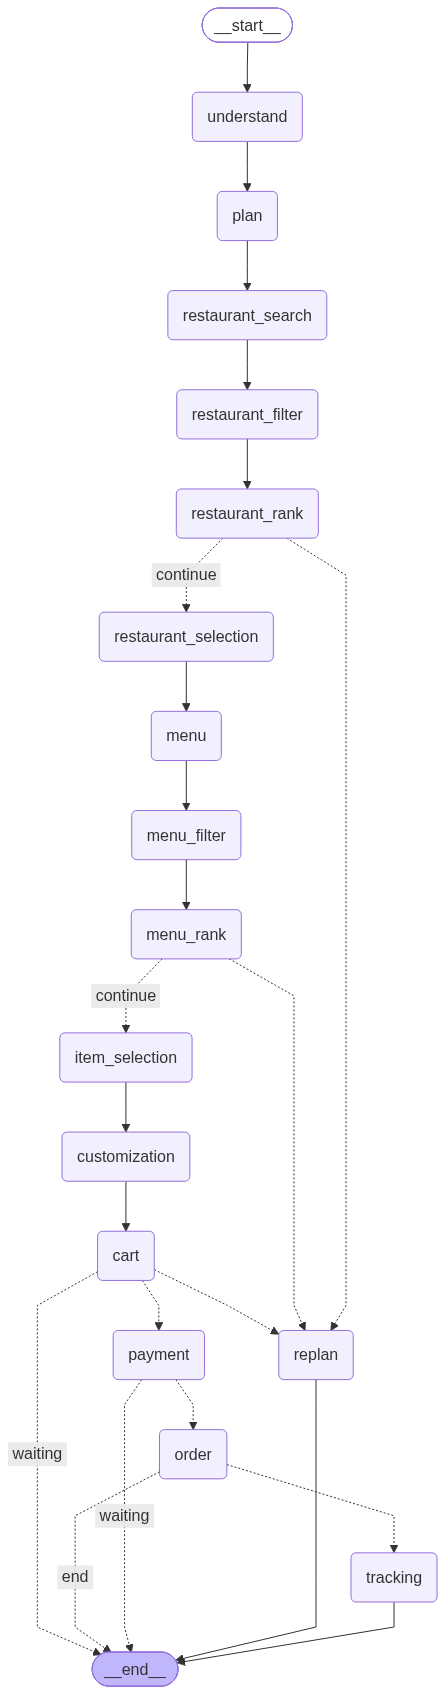

In [301]:
# ============================================
# CELL 57 — DISPLAY GRAPH
# ============================================

try:

    from IPython.display import Image, display

    image_bytes = (
        food_agent
        .get_graph()
        .draw_mermaid_png()
    )

    display(Image(image_bytes))

except Exception as e:

    print(
        "Graph image unavailable:",
        e
    )

    print(
        "The compiled graph is still valid."
    )

# 17. JURY DEMO REQUEST

Run the agent with the exact natural-language request.

The agent will use the **real selected Swiggy address** and **real Swiggy search tools**.

In [302]:
# ============================================
# DIAGNOSTIC — DIRECT MENU SEARCH
# ============================================

restaurant_id = result.get(
    "selected_restaurant_id"
)

address_id = result.get(
    "selected_address_id"
)

print(
    "Restaurant:",
    result.get(
        "selected_restaurant",
        {}
    ).get("name")
)

print(
    "Restaurant ID:",
    restaurant_id
)

print(
    "Address ID:",
    address_id
)

print(
    "\nCalling REAL search_menu..."
)

direct_menu_result = await invoke_mcp(
    "search_menu",
    {
        "addressId":
            address_id,

        "query":
            "pizza",

        "restaurantIdOfAddedItem":
            str(
                restaurant_id
            ),

        "vegFilter":
            1,

        "offset":
            0
    }
)

print(
    "\nRAW SWIGGY RESPONSE:"
)

print(
    extract_text(
        direct_menu_result
    )[:10000]
)

print(
    "\nPARSED ITEMS:"
)

direct_items = parse_menu_response(
    direct_menu_result
)

print(
    "Count:",
    len(direct_items)
)

for item in direct_items:

    print(
        f"{item['name']} | "
        f"₹{item['price']} | "
        f"{'VEG' if item['is_veg'] else 'NON-VEG'} | "
        f"{item['item_id']}"
    )

Restaurant: Zulu's Pizza - Fresh Fanatics
Restaurant ID: 1151914
Address ID: d83jf2v2na8qh76h8peg__ARt92ARpE9YswhL_9cmG50

Calling REAL search_menu...

RAW SWIGGY RESPONSE:
Found 10 menu items for "pizza":
1. OG Margherita Pizza [7" Regular] — ₹198 | Veg | 4.9★ (17) (ID: 179098835)
   Variants: [Pan Tossed (group:64048553, var:195457052), Thin Crust (group:64048553, var:195457059), Cheese Blast ₹50 (group:64048553, var:195457068), Thin Crust Cheese Blast ₹50 (group:64048553, var:195457075)]
2. Corn & Cheese Pizza [7" Regular] — ₹238 | Veg | 4.8★ (23) (ID: 179098885)
   Variants: [Pan Tossed (group:64048590, var:195457184), Thin Crust (group:64048590, var:195457190), Cheese Blast ₹50 (group:64048590, var:195457194), Thin Crust Cheese Blast ₹50 (group:64048590, var:195457198)]
3. Tikka Paneer Pizza [7" Regular] — ₹318 | Veg | 5.0★ (6) (ID: 179099012)
   Variants: [Pan Tossed (group:64048692, var:195457537), Thin Crust (group:64048692, var:195457545), Cheese Blast ₹50 (group:64048692, var

In [304]:
# ============================================
# CELL 59 — RUN JURY DEMO
# ============================================

jury_request = (
    "I want a vegetarian pizza "
    "under ₹500 delivered within "
    "30 minutes."
)

initial_state = AgentState(

    user_request=
        jury_request,

    selected_address_id=
        selected_address_id,

    user_confirmation=
        False,

    needs_user_input=
        False,

    replanning_required=
        False,

    current_step=
        "START"
)


print(
    "============================================"
)

print(
    "USER REQUEST"
)

print(
    "============================================"
)

print(
    jury_request
)

print(
    "\n============================================"
)

print(
    "AGENT EXECUTION"
)

print(
    "============================================"
)


try:

    result = await food_agent.ainvoke(
        initial_state
    )

except Exception as e:

    print(
        "\n❌ AGENT EXECUTION FAILED"
    )

    print(
        "Error type:",
        type(e).__name__
    )

    print(
        "Error:",
        str(e)
    )

    raise


print(
    "\n============================================"
)

print(
    "AGENT FINISHED THIS TURN"
)

print(
    "============================================"
)

print(
    "Current step:",
    result.get(
        "current_step"
    )
)

print(
    "Selected restaurant:",
    result.get(
        "selected_restaurant",
        {}
    ).get(
        "name"
    )
)

print(
    "Selected item:",
    result.get(
        "selected_item",
        {}
    ).get(
        "name"
    )
)

print(
    "Item price:",
    result.get(
        "selected_item",
        {}
    ).get(
        "price"
    )
)

print(
    "Needs user input:",
    result.get(
        "needs_user_input"
    )
)

print(
    "Replanning required:",
    result.get(
        "replanning_required"
    )
)

print(
    "Order status:",
    result.get(
        "order_status"
    )
)

USER REQUEST
I want a vegetarian pizza under ₹500 delivered within 30 minutes.

AGENT EXECUTION
🧠 UNDERSTAND
{
  "food": "pizza",
  "vegetarian": true,
  "max_budget": 500,
  "max_delivery_minutes": 30
}
🗺️ CREATE TASK PLAN
1. Get address
2. Search restaurants
3. Filter hard constraints
4. Rank restaurants
5. Select restaurant
6. Search menu
7. Filter menu items
8. Rank menu items
9. Select item
10. Check customization
11. Update cart
12. Get payment options
13. Ask confirmation
14. Place order
15. Track order
🍽️ SEARCH RESTAURANTS
Search query: pizza
✓ Real Swiggy restaurant search completed

🔎 FILTER RESTAURANTS
❌ Falahaar: 46 min > 30 min
❌ Nomad Pizza - Traveller Series: 58 min > 30 min
❌ ENSO - Sourdough Pizza by Nomad: 53 min > 30 min
❌ Crusto's - Cheese Burst Pizza By Olio: 33 min > 30 min

Restaurants returned: 10
Restaurants after filter: 6
✓ Circle Of Crust | Pizzas, Italian, Beverages, Desserts | 4.1★ | 28 min | OPEN
✓ Domino's Pizza | Pizzas | 4.4★ | 25 min | OPEN
✓ Pizza H

In [166]:
import inspect

source = inspect.getsource(menu_filter_node)

print("food_aliases" in source)

False


# 18.  SUMMARY

In [305]:
# ============================================
# CELL 61 — SHOW AGENT DECISIONS
# ============================================

req = result.get(
    "requirements",
    {}
)

restaurant = result.get(
    "selected_restaurant",
    {}
)

item = result.get(
    "selected_item",
    {}
)

print("╔══════════════════════════════════════════╗")
print("║       FOOD ORDERING AGENT               ║")
print("╚══════════════════════════════════════════╝")

print("\n🧠 UNDERSTAND")
print("Food:", req.get("food"))
print("Vegetarian:", req.get("vegetarian"))
print("Budget:", req.get("max_budget"))
print(
    "Max delivery:",
    req.get("max_delivery_minutes"),
    "minutes"
)

print("\n🏪 RESTAURANT")
print("Name:", restaurant.get("name"))
print("Rating:", restaurant.get("rating"))
print(
    "Delivery:",
    restaurant.get("delivery_minutes"),
    "minutes"
)

print("\n🍽️ ITEM")
print("Name:", item.get("name"))
print("Price:", item.get("price"))

print("\n📍 ADDRESS")
print(
    "Real Swiggy address ID:",
    result.get("selected_address_id")
)

print("\n🤖 CONTROL")
print(
    "Current step:",
    result.get("current_step")
)
print(
    "Needs user input:",
    result.get("needs_user_input")
)

╔══════════════════════════════════════════╗
║       FOOD ORDERING AGENT               ║
╚══════════════════════════════════════════╝

🧠 UNDERSTAND
Food: pizza
Vegetarian: True
Budget: 500
Max delivery: 30 minutes

🏪 RESTAURANT
Name: Zulu's Pizza - Fresh Fanatics
Rating: 4.8
Delivery: 25 minutes

🍽️ ITEM
Name: OG Margherita Pizza [7" Regular]
Price: 198.0

📍 ADDRESS
Real Swiggy address ID: d83jf2v2na8qh76h8peg__ARt92ARpE9YswhL_9cmG50

🤖 CONTROL
Current step: PAYMENT
Needs user input: True
